In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import os
import numpy as np

os.chdir("..")

In [2]:
dataset_path = Path("dataset/CamVid")

train_dir = dataset_path / "train"
train_labels_dir = dataset_path / "train_labels"
test_dir = dataset_path / "test"
test_labels_dir = dataset_path / "test_labels"
val_dir = dataset_path / "val"
val_labels_dir = dataset_path / "val_labels"

class_dir = dataset_path / "class_dict.csv"

In [3]:
print(f"Train images: {len(list(train_dir.glob('*.png')))}")
print(f"Train masks: {len(list(train_labels_dir.glob('*.png')))}")

print(f"Val images: {len(list(val_dir.glob('*.png')))}")
print(f"Val masks: {len(list(val_labels_dir.glob('*.png')))}")

print(f"Test images: {len(list(test_dir.glob('*.png')))}")
print(f"Test masks: {len(list(test_labels_dir.glob('*.png')))}")

print(f"Classes: {len(pd.read_csv(class_dir))}")

Train images: 369
Train masks: 369
Val images: 100
Val masks: 100
Test images: 232
Test masks: 232
Classes: 32


## images with labels

In [4]:
ids={}
for image in train_dir.iterdir():
    image = image.name
    if image[:-4] not in ids:
        ids[image[:-4]] = 1
    else:
        ids[image[:-4]] += 1
        print(f"Image {image} has {ids[image[:-4]]} duplicates")
for mask in train_labels_dir.iterdir():
    mask = mask.name
    if mask[:-6] not in ids:
        print(f"Mask {mask} has no corresponding image")

In [5]:
ids={}
for image in val_dir.iterdir():
    image = image.name
    if image[:-4] not in ids:
        ids[image[:-4]] = 1
    else:
        ids[image[:-4]] += 1
        print(f"Image {image} has {ids[image[:-4]]} duplicates")
for mask in val_labels_dir.iterdir():
    mask = mask.name
    if mask[:-6] not in ids:
        print(f"Mask {mask} has no corresponding image")

In [6]:
ids={}
for image in test_dir.iterdir():
    image = image.name
    if image[:-4] not in ids:
        ids[image[:-4]] = 1
    else:
        ids[image[:-4]] += 1
        print(f"Image {image} has {ids[image[:-4]]} duplicates")
for mask in test_labels_dir.iterdir():
    mask = mask.name
    if mask[:-6] not in ids:
        print(f"Mask {mask} has no corresponding image")

## image vis

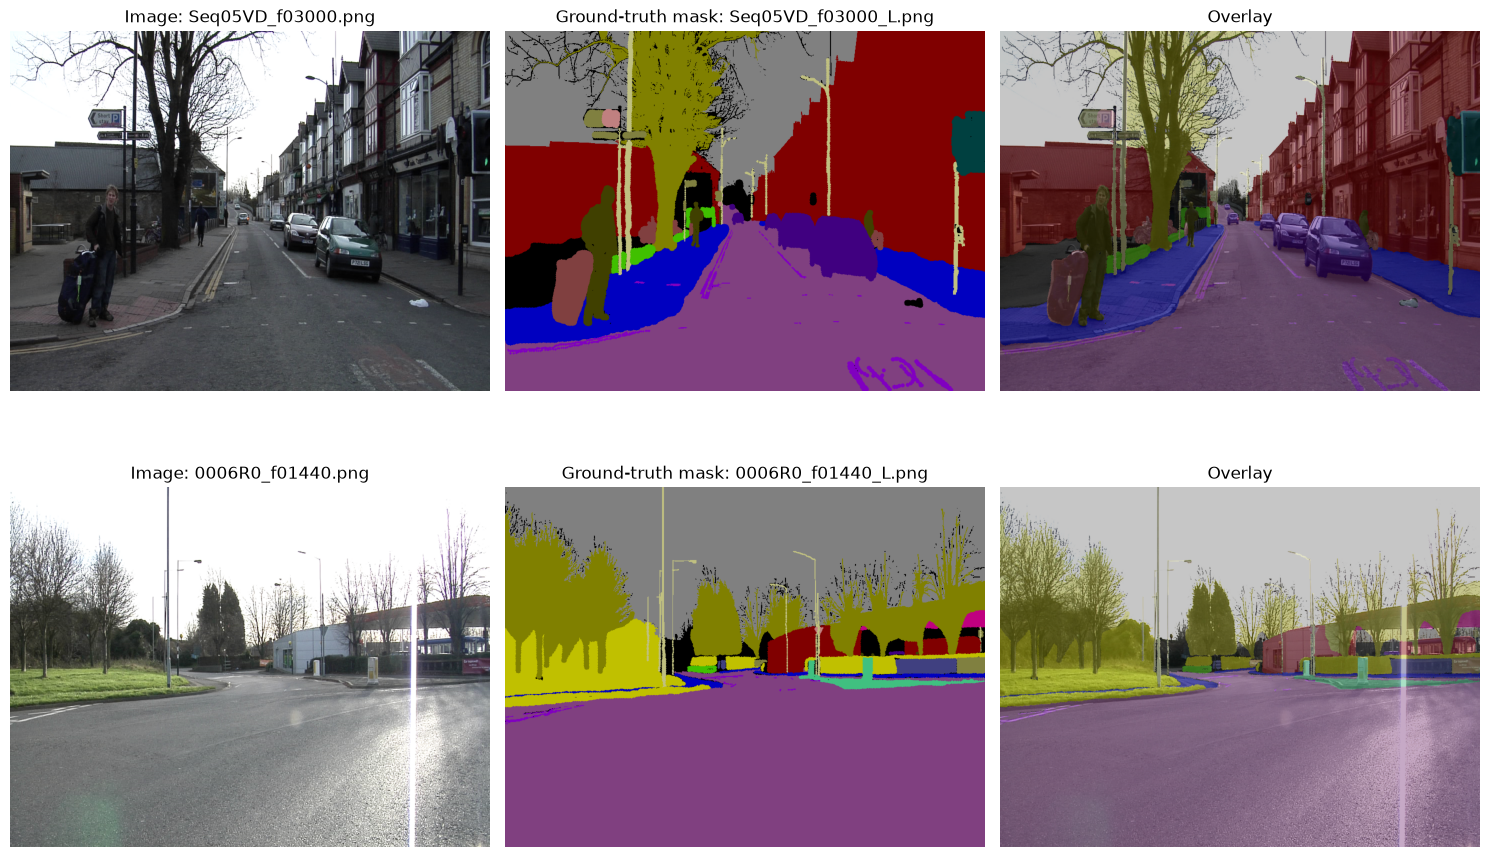

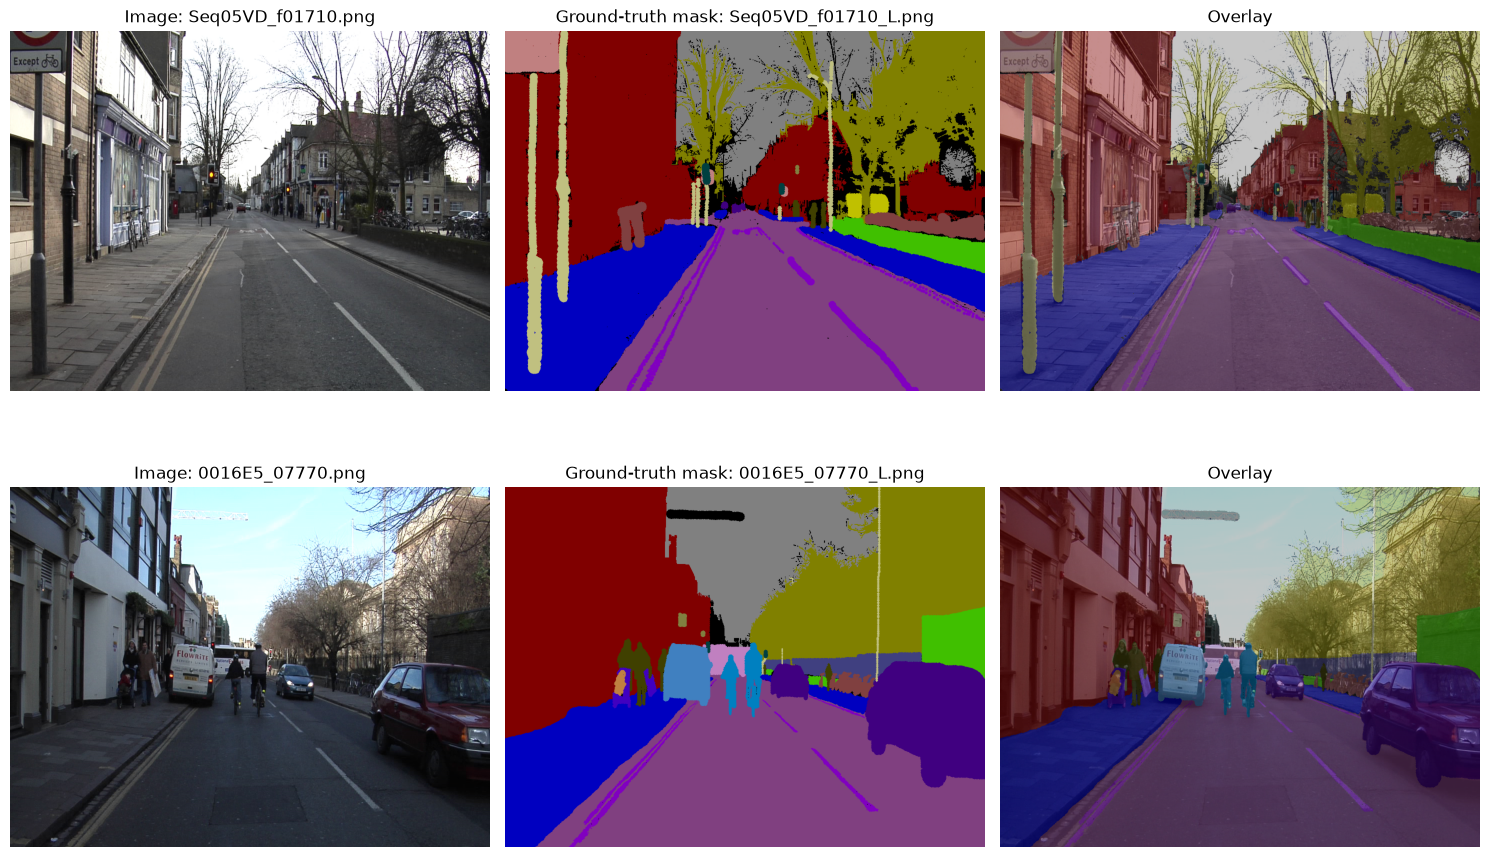

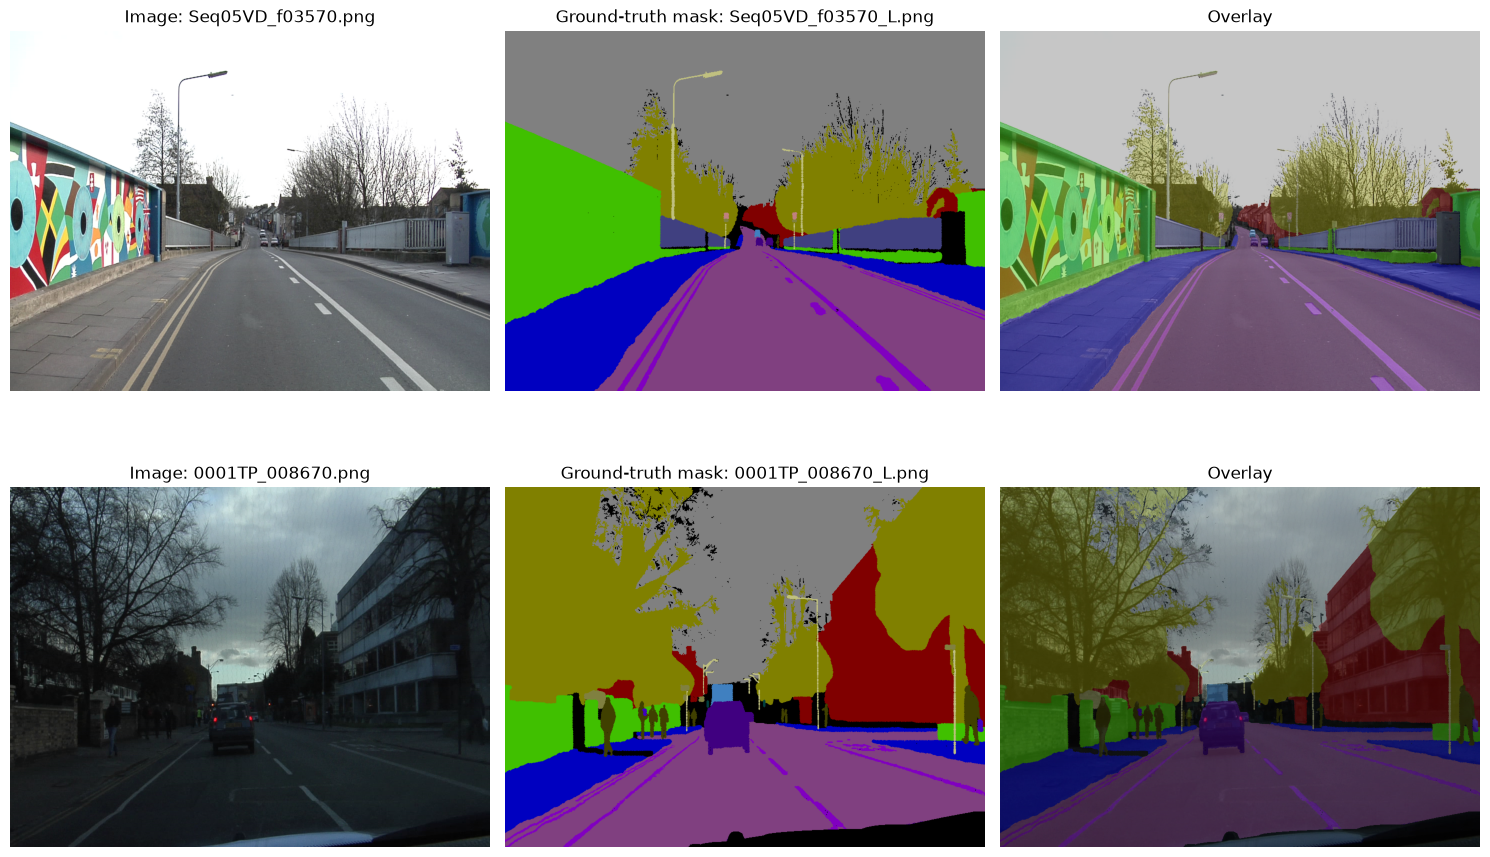

In [7]:
def show_samples(split="train", n=4, seed=42):
    if split == "train":
        image_dir = train_dir
        mask_dir = train_labels_dir
    elif split == "val":
        image_dir = val_dir
        mask_dir = val_labels_dir
    elif split == "test":
        image_dir = test_dir
        mask_dir = test_labels_dir


    pairs = list(zip(sorted(image_dir.iterdir()), sorted(mask_dir.iterdir())))
    selected_indices = np.random.RandomState(seed).choice(len(pairs), size=n, replace=False)

    fig, axes = plt.subplots(n, 3, figsize=(15, 5 * n))

    for row, idx in enumerate(selected_indices):
        image_path, mask_path = pairs[idx]

        image = np.asarray(Image.open(image_path).convert("RGB"))
        mask = np.asarray(Image.open(mask_path).convert("RGB"))

        axes[row, 0].imshow(image)
        axes[row, 0].set_title(f"Image: {image_path.name}")

        axes[row, 1].imshow(mask)
        axes[row, 1].set_title(f"Ground-truth mask: {mask_path.name}")

        axes[row, 2].imshow(image)
        axes[row, 2].imshow(mask, alpha=0.45)
        axes[row, 2].set_title("Overlay")

        for ax in axes[row]:
            ax.axis("off")

    plt.tight_layout()
    plt.show()


show_samples("train", n=2)
show_samples("val", n=2)
show_samples("test", n=2)

## class labels

In [8]:
df = pd.read_csv(class_dir)
df

,name,r,g,b
0,Animal,64,128,64
1,Archway,192,0,128
2,Bicyclist,0,128,192
3,Bridge,0,128,64
4,Building,128,0,0
5,Car,64,0,128
6,CartLuggagePram,64,0,192
7,Child,192,128,64
8,Column_Pole,192,192,128
9,Fence,64,64,128
